In [1]:
from syntraj_utileval.datasets.dataset import TrajectoryDataset

from syntraj_utileval.suite.suite import (
    EvaluationSuite,
    EvalParams,
)
import pandas as pd

import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)


def uniform_datetime_df(df, hour_col=None, day_col=None):
    if hour_col is not None and day_col is not None:
        df["datetime"] = (
            pd.to_datetime("2024-01-01")
            + pd.to_timedelta(df[day_col], unit="D")
            + pd.to_timedelta(df[hour_col], unit="h")
        )
        df = df.drop(columns=[hour_col, day_col])
        return df


def show_results(res_dict, dataset_names, data_name, header="Trajectory level"):
    result_df = pd.DataFrame(res_dict)

    result_df.index = dataset_names
    if result_df.shape[1] == 1:
        header_df = pd.DataFrame(
            [[f"{header} ({data_name})"] + [""] * (result_df.shape[1] - 1)],
            columns=result_df.columns,
        )

    else:
        header_df = pd.DataFrame(
            [[""] + [f"{header} ({data_name})"] + [""] * (result_df.shape[1] - 2)],
            columns=result_df.columns,
        )

    result_df = pd.concat([header_df, result_df])
    return result_df


In [2]:
df_original_FS = pd.read_csv("../data/weeklyFS-NYC/test_latlon.csv")
df_syn_FS_LSTMTraj_best = pd.read_csv(
    r"../gen_data/LSTM-TrajGAN/syn_traj_test_weekly_FS-NYC_2000.csv"
)
df_syn_FS_exGAN_best = pd.read_csv(
    r"../gen_data/exGAN/syn_traj_test_4_weekly_FS-NYC_2000.csv"
)


df_syn_FS_TrajGDM_best_20 = pd.read_csv(
    r"..\gen_data\TrajGDM\weekly_FSNYC\syn_traj_test_l20_e397_new.csv"
)

df_original_FS = uniform_datetime_df(df_original_FS, hour_col="hour", day_col="day")
df_syn_FS_LSTMTraj_best = uniform_datetime_df(
    df_syn_FS_LSTMTraj_best, hour_col="hour", day_col="day"
)
df_syn_FS_exGAN_best = uniform_datetime_df(
    df_syn_FS_exGAN_best, hour_col="hour", day_col="day"
)

In [3]:
params = EvalParams(cell_width_m=500, cell_height_m=500)
orig_FS = TrajectoryDataset(
    df=df_original_FS,
    dataset_name="original",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)
LSTM_Traj_FS = TrajectoryDataset(
    df=df_syn_FS_LSTMTraj_best,
    dataset_name="LSTM-TrajGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)

exGAN_FS = TrajectoryDataset(
    df=df_syn_FS_exGAN_best,
    dataset_name="exGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)

trajGDM20_FS = TrajectoryDataset(
    df=df_syn_FS_TrajGDM_best_20,
    dataset_name="TrajGDM_20",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
)

synthetics_FS = [
    orig_FS,
    LSTM_Traj_FS,
    exGAN_FS,
    trajGDM20_FS,
]

suite_FS = EvaluationSuite(
    original=orig_FS, synthetics=synthetics_FS, params=params, data_name="Weekly FS-NYC"
)

Spatial sensitivity analysis on Original data...
Optimal cell edge length is somewhere between: 385m and 860m
Midpoint cel edge: 485m with a step to grid ratio (SGR) of 2.2671575129303663 


In [5]:
# ******* Trajectory-level metrics ********
traj_results_FS = {}
df_results_traj = pd.DataFrame()
traj_results_FS["I-rank (W1)"] = suite_FS.evaluate_I_rank()
traj_results_FS["cosine_category (W1)"] = suite_FS.evaluate_pairwise_trajectory_dist(
    distance="cosine_category", normalize_0_1=True, n_jobs=-1
)
traj_results_FS["traj_implausibility (rate)"] = suite_FS.evaluate_trajectory_plausibility(verbose=False)


traj_results_FS["traj clustering (Silhouette score)"] = [
    data_result["Silhouette"]
    for data_result in suite_FS.evaluate_trajectory_clustering_prediction()
]

# ***************** Point-level metrics ********
point_results_FS = {}
point_results_FS["categorical G-rank (tau)"] = suite_FS.evaluate_cat_G_rank(n_cat=10)
point_results_FS["transition probability (W1)"] = suite_FS.evaluate_transtion_matrix(
    normalize_0_1=True
)
point_results_FS["category-location match"] = [
    data_result["match_rate"]
    for data_result in suite_FS.evaluate_category_loc_top1_match()
]
point_results_FS["global flow prediction (W1)"] = [
    data_result["Sequential_Flow_WD"]
    for data_result in suite_FS.evaluate_global_flow_prediction(normalize_0_1=True)
]

**Finished calculating I_rank in 0 minutes 4 seconds**
**Finished calculating pairwise_trajectory_dist in 3 minutes 28 seconds**
**Finished calculating trajectory_plausibility in 3 minutes 24 seconds**
**Finished calculating trajectory_clustering_prediction in 0 minutes 0 seconds**
**Finished calculating cat_G_rank in 0 minutes 0 seconds**
**Finished calculating transtion_matrix in 0 minutes 3 seconds**
**Finished calculating category_loc_top1_match in 0 minutes 0 seconds**
**Finished calculating global_flow_prediction in 0 minutes 47 seconds**


In [6]:
traj_results_df = show_results(
    traj_results_FS,
    [d.dataset_name for d in suite_FS.synthetics],
    suite_FS.data_name,
    header="Trajectory level",
)
display(traj_results_df)
point_results_df = show_results(
    point_results_FS,
    [d.dataset_name for d in suite_FS.synthetics],
    suite_FS.data_name,
    header="Point level",
)
display(point_results_df)

,I-rank (W1),cosine_category (W1),traj_implausibility (rate),traj clustering (Silhouette score)
0,,Trajectory level (Weekly FS-NYC),,
original,0.0,0.0,0.075949,0.595272
LSTM-TrajGAN,0.078123,0.006751,0.563778,0.174385
exGAN,0.120782,0.000645,0.613437,0.543116
TrajGDM_20,0.015689,N/A,0.321324,0.393196


,categorical G-rank (tau),transition probability (W1),category-location match,global flow prediction (W1)
0,,Point level (Weekly FS-NYC),,
original,1.0,0.0,1.0,0.015426
LSTM-TrajGAN,0.511111,0.190267,0.256711,0.02623
exGAN,0.822222,0.171649,0.260067,0.029497
TrajGDM_20,N/A,0.61149,N/A,0.052564


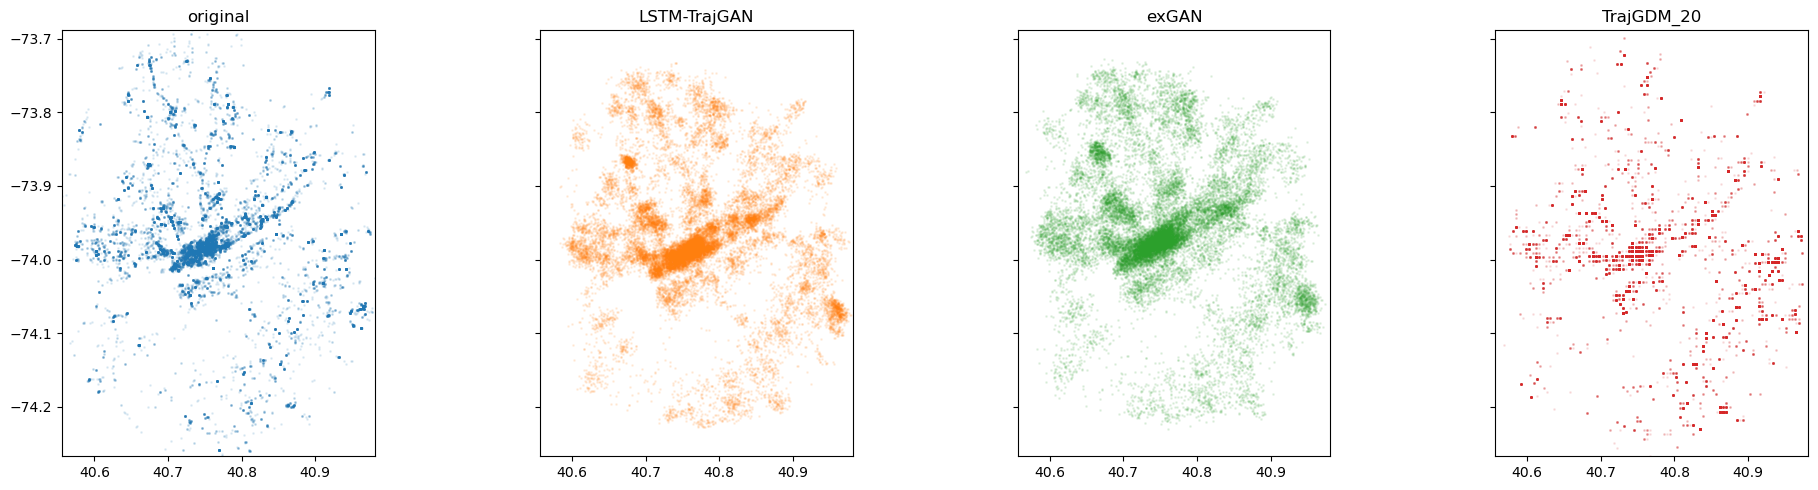

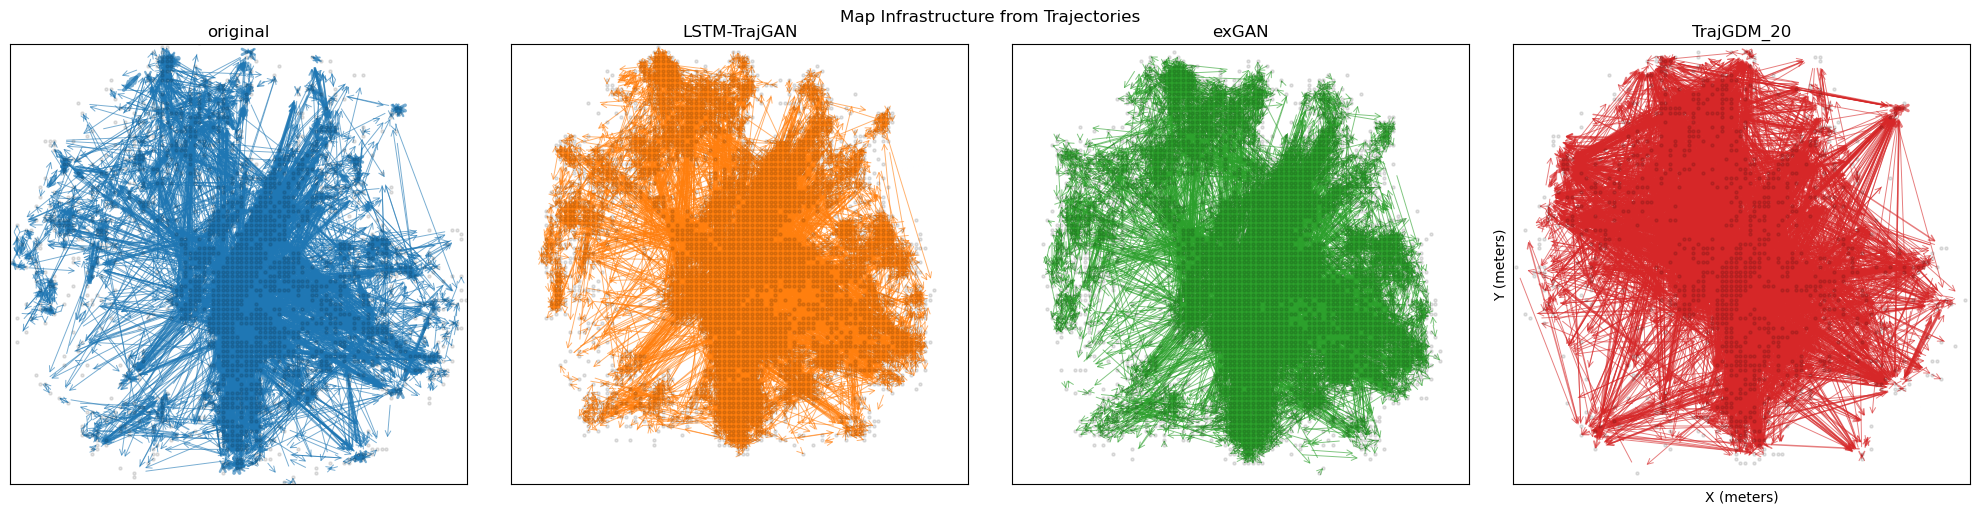

In [ ]:
# the spatial scale in the same across datasets
suite_FS.visualize_point_density()
suite_FS.visualize_map_infrastructure()

## Case B

In [4]:
df_original_Dgeo = pd.read_csv(r"..\..\Data\daily_geolife\test_latlon.csv")
df_syn_Dgeo_LSTMTraj_best = pd.read_csv(
    r"../gen_data/LSTM-TrajGAN/syn_traj_test_daily_geolife_3000.csv"
)
df_syn_Dgeo_exGAN_best = pd.read_csv(
    r"../gen_data/exGAN/syn_traj_test_4_daily_geolife_3000.csv"
)

df_syn_Dgeo_TrajGDM_best_50 = pd.read_csv(
    r"../gen_data/TrajGDM\daily_geolife\syn_traj_test_l20_e226.csv"
)

df_original_Dgeo = uniform_datetime_df(df_original_Dgeo, hour_col="hour", day_col="day")
df_syn_Dgeo_LSTMTraj_best = uniform_datetime_df(
    df_syn_Dgeo_LSTMTraj_best, hour_col="hour", day_col="day"
)
df_syn_Dgeo_exGAN_best = uniform_datetime_df(
    df_syn_Dgeo_exGAN_best, hour_col="hour", day_col="day"
)


In [5]:
params = EvalParams(cell_width_m=350, cell_height_m=350)
orig_Dgeo = TrajectoryDataset(
    df=df_original_Dgeo,
    dataset_name="original",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)
LSTM_Traj_Dgeo = TrajectoryDataset(
    df=df_syn_Dgeo_LSTMTraj_best,
    dataset_name="LSTM-TrajGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)

exGAN_Dgeo = TrajectoryDataset(
    df=df_syn_Dgeo_exGAN_best,
    dataset_name="exGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)


TrajGDM20_Dgeo = TrajectoryDataset(
    df=df_syn_Dgeo_TrajGDM_best_50,
    dataset_name="TrajGDM_20",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
)


synthetics_Dgeo = [orig_Dgeo, LSTM_Traj_Dgeo, exGAN_Dgeo, TrajGDM20_Dgeo]

suite_Dgeo = EvaluationSuite(
    original=orig_Dgeo,
    synthetics=synthetics_Dgeo,
    params=params,
    data_name="daily_geolife",
)

Spatial sensitivity analysis on Original data...
Optimal cell edge length is somewhere between: 255m and 780m
Midpoint cel edge: 355m with a step to grid ratio (SGR) of 2.3687649037334517 


In [ ]:
# ******* Trajectory-level metrics ********
traj_results_Dgeo = {}
traj_results_Dgeo["average speed (km/h)"] = suite_Dgeo.evaluate_average_speed()

traj_results_Dgeo["pairwise Hausdorff (W1)"] = (
    suite_Dgeo.evaluate_pairwise_trajectory_dist(
        distance="hausdorff", normalize_0_1=True, n_jobs=-1
    )
)
traj_results_Dgeo["evaluate_map_reconstruction(mean distance)"] = (
    suite_Dgeo.evaluate_traj_network_displacement(on_road_key=0,verbose = False)
)

traj_results_Dgeo["next loc pred (mean accuracy)"] = [
    data_result["mean topk accuracy"]
    for data_result in suite_Dgeo.evaluate_trajectory_next_location_prediction(
        k=5, normalize_0_1=True
    )
]

# ***************** Point-level metrics ********
point_results_Dgeo = {}
point_results_Dgeo["G-rank (tau)"] = suite_Dgeo.evaluate_G_rank(n_cat=10)
point_results_Dgeo["transition probability (W1)"] = suite_Dgeo.evaluate_transtion_matrix(
    normalize_0_1=True
)
point_results_Dgeo["location implausability rate"] = [
    data_result["Implausibility_rate"]
    for data_result in suite_Dgeo.evaluate_location_plausibility(verbose = False)
]

point_results_Dgeo["global flow prediction (W1)"] = [
    data_result["Sequential_Flow_WD"]
    for data_result in suite_Dgeo.evaluate_global_flow_prediction(normalize_0_1=True)
]

**Finished calculating average_speed in 0 minutes 0 seconds**
**Finished calculating pairwise_trajectory_dist in 2 minutes 34 seconds**


20008it [00:00, 48343.78it/s]


**Finished calculating map reconstruction in 2 minutes 40 seconds**
**Finished calculating trajectory_next_location_prediction in 0 minutes 11 seconds**
**Finished calculating G_rank in 0 minutes 0 seconds**
**Finished calculating transtion_matrix in 0 minutes 7 seconds**


**Finished calculating location_plausibility in 1 minutes 5 seconds**
**Finished calculating global_flow_prediction in 2 minutes 2 seconds**


In [7]:
Dgeo_traj_results_df = show_results(
    traj_results_Dgeo,
    [d.dataset_name for d in suite_Dgeo.synthetics],
    suite_Dgeo.data_name,
    header="Trajectory level",
)
display(Dgeo_traj_results_df.round(4))
Dgeo_point_results_df = show_results(
    point_results_Dgeo,
    [d.dataset_name for d in suite_Dgeo.synthetics],
    suite_Dgeo.data_name,
    header="Point level",
)
display(Dgeo_point_results_df.round(4))

,average speed (km/h),pairwise Hausdorff (W1),evaluate_map_reconstruction (mean distance),next loc pred (mean accuracy)
0,,Trajectory level (daily_geolife),,
original,0.0,0.0,0.051738,0.513264
LSTM-TrajGAN,1.163783,0.002183,0.128566,0.130407
exGAN,0.689565,0.001897,0.133408,0.143973
TrajGDM_20,N/A,0.175105,1.673456,0.049676


,G-rank (tau),transition probability (W1),location implausability rate,global flow prediction (W1)
0,,Point level (daily_geolife),,
original,1.0,0.0,0.003016,0.005074
LSTM-TrajGAN,-0.001431,0.157485,0.019207,0.012467
exGAN,-0.000209,0.172532,0.019384,0.012836
TrajGDM_20,-0.289801,0.652273,0.124073,0.032149


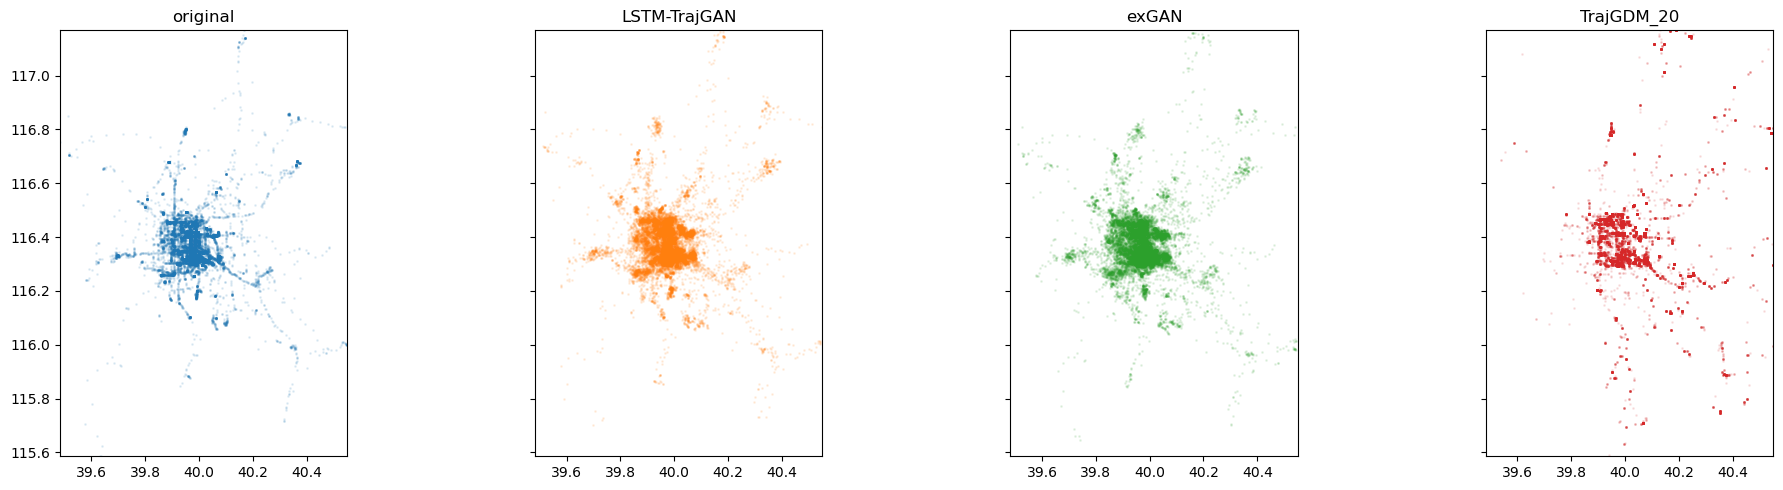

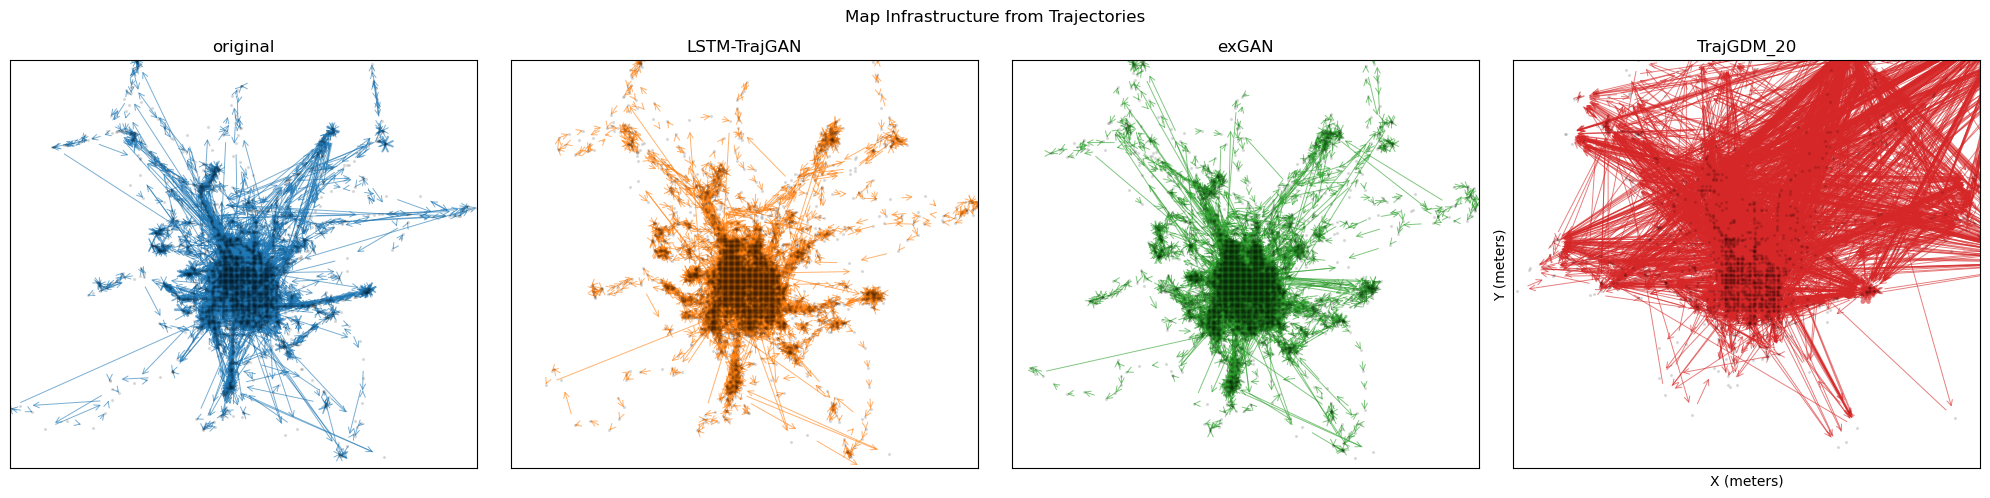

In [15]:
# the spatial scale in the same across datasets
suite_Dgeo.visualize_point_density()
suite_Dgeo.visualize_map_infrastructure()

## Weekly and Hourly Geolife

#### Hourly geolife

In [3]:
df_original_Hgeo = pd.read_csv(r"..\..\Data\hourly_geolife\test_latlon.csv")

df_syn_Hgeo_LSTMTraj_best = pd.read_csv(
    r"../gen_data/LSTM-TrajGAN/syn_traj_test_hourly_geolife_3000.csv"
)
df_syn_Hgeo_exGAN_best = pd.read_csv(
    r"../gen_data/exGAN/syn_traj_test_4_hourly_geolife_3000.csv"
)

df_syn_Hgeo_TrajGDM_best_50 = pd.read_csv(
    r"..\gen_data\TrajGDM\hourly_geolife\syn_traj_test_l50_e391.csv"
)

df_original_Hgeo = uniform_datetime_df(df_original_Hgeo, hour_col="hour", day_col="day")
df_syn_Hgeo_LSTMTraj_best = uniform_datetime_df(
    df_syn_Hgeo_LSTMTraj_best, hour_col="hour", day_col="day"
)
df_syn_Hgeo_exGAN_best = uniform_datetime_df(
    df_syn_Hgeo_exGAN_best, hour_col="hour", day_col="day"
)

In [4]:
params = EvalParams(cell_width_m=100, cell_height_m=100)
orig_Hgeo = TrajectoryDataset(
    df=df_original_Hgeo,
    dataset_name="original",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)
LSTM_Traj_Hgeo = TrajectoryDataset(
    df=df_syn_Hgeo_LSTMTraj_best,
    dataset_name="LSTM-TrajGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)

exGAN_Hgeo = TrajectoryDataset(
    df=df_syn_Hgeo_exGAN_best,
    dataset_name="exGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)


TrajGDM50_Hgeo = TrajectoryDataset(
    df=df_syn_Hgeo_TrajGDM_best_50,
    dataset_name="TrajGDM_50",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
)


synthetics_Hgeo = [orig_Hgeo, LSTM_Traj_Hgeo, exGAN_Hgeo, TrajGDM50_Hgeo]

suite_Hgeo = EvaluationSuite(
    original=orig_Hgeo,
    synthetics=synthetics_Hgeo,
    params=params,
    data_name="hourly_geolife",
)

Spatial sensitivity analysis on Original data...
Optimal cell edge length is somewhere between: 105m and 105m
Midpoint cel edge: 105m with a step to grid ratio (SGR) of 1.2828981504387216 


In [ ]:
# ******* Trajectory-level metrics ********
traj_results_Hgeo = {}


traj_results_Hgeo["Traj Lengths (W1: km)"] = suite_Hgeo.evaluate_trajectory_lengths()
traj_results_Hgeo["pairwise Hausdorff (W1)"] = (
    suite_Hgeo.evaluate_pairwise_trajectory_dist(
        distance="hausdorff", normalize_0_1=True, n_jobs=-1
    )
)
traj_results_Hgeo["evaluate_map_reconstruction (mean distance)"] = (
    suite_Hgeo.evaluate_traj_network_displacement(on_road_key=0,verbose = False)
)

traj_results_Hgeo["next loc prediction (mean accuracy)"] = [
    data_result["mean topk accuracy"]
    for data_result in suite_Hgeo.evaluate_trajectory_next_location_prediction(
        k=10, normalize_0_1=True
    )
]

# ***************** Point-level metrics ********
point_results_Hgeo = {}
point_results_Hgeo["G-rank (tau)"] = suite_Hgeo.evaluate_G_rank(n_cat=10)
point_results_Hgeo["transition probability (W1)"] = suite_Hgeo.evaluate_transtion_matrix(normalize_0_1=True)
point_results_Hgeo["location plausability rate"] = [
    data_result["Implausibility_rate"]
    for data_result in suite_Hgeo.evaluate_location_plausibility(verbose = False)
]

point_results_Hgeo["global flow prediction (W1)"] = [
    data_result["Sequential_Flow_WD"]
    for data_result in suite_Hgeo.evaluate_global_flow_prediction(normalize_0_1=True)
]

**Finished calculating trajectory_lengths in 0 minutes 0 seconds**
**Finished calculating pairwise_trajectory_dist in 52 minutes 19 seconds**


281611it [00:04, 63550.81it/s]


**Finished calculating map_reconstruction in 4 minutes 55 seconds**
**Finished calculating trajectory_next_location_prediction in 18 minutes 46 seconds**
**Finished calculating G_rank in 0 minutes 0 seconds**
**Finished calculating transtion_matrix in 12 minutes 47 seconds**
**Finished calculating location_plausibility in 2 minutes 16 seconds**


**Finished calculating global_flow_prediction in 519 minutes 25 seconds**


In [6]:
Hgeo_traj_results_df = show_results(
    traj_results_Hgeo,
    [d.dataset_name for d in suite_Hgeo.synthetics],
    suite_Hgeo.data_name,
    header="Trajectory level",
)
display(Hgeo_traj_results_df.round(4))
Hgeo_point_results_df = show_results(
    point_results_Hgeo,
    [d.dataset_name for d in suite_Hgeo.synthetics],
    suite_Hgeo.data_name,
    header="Point level",
)
display(Hgeo_point_results_df.round(4))

,Traj Lengths (W1: km),pairwise Hausdorff (W1),evaluate_map_reconstruction (mean distance),next loc prediction (mean accuracy)
0,,Trajectory level (hourly_geolife),,
original,0.0,0.0,0.045669,0.845236
LSTM-TrajGAN,4.864312,0.002006,0.124419,0.178659
exGAN,3.881354,0.001521,0.118012,0.279026
TrajGDM_50,234.176142,0.066812,0.852424,0.007164


,G-rank (tau),transition probability (W1),location plausability rate,global flow prediction (W1)
0,,Point level (hourly_geolife),,
original,1.0,0.0,0.004017,0.001074
LSTM-TrajGAN,-0.217746,0.226706,0.020907,0.006261
exGAN,-0.169902,0.182076,0.020101,0.005389
TrajGDM_50,-0.369606,0.970657,0.055325,0.053111


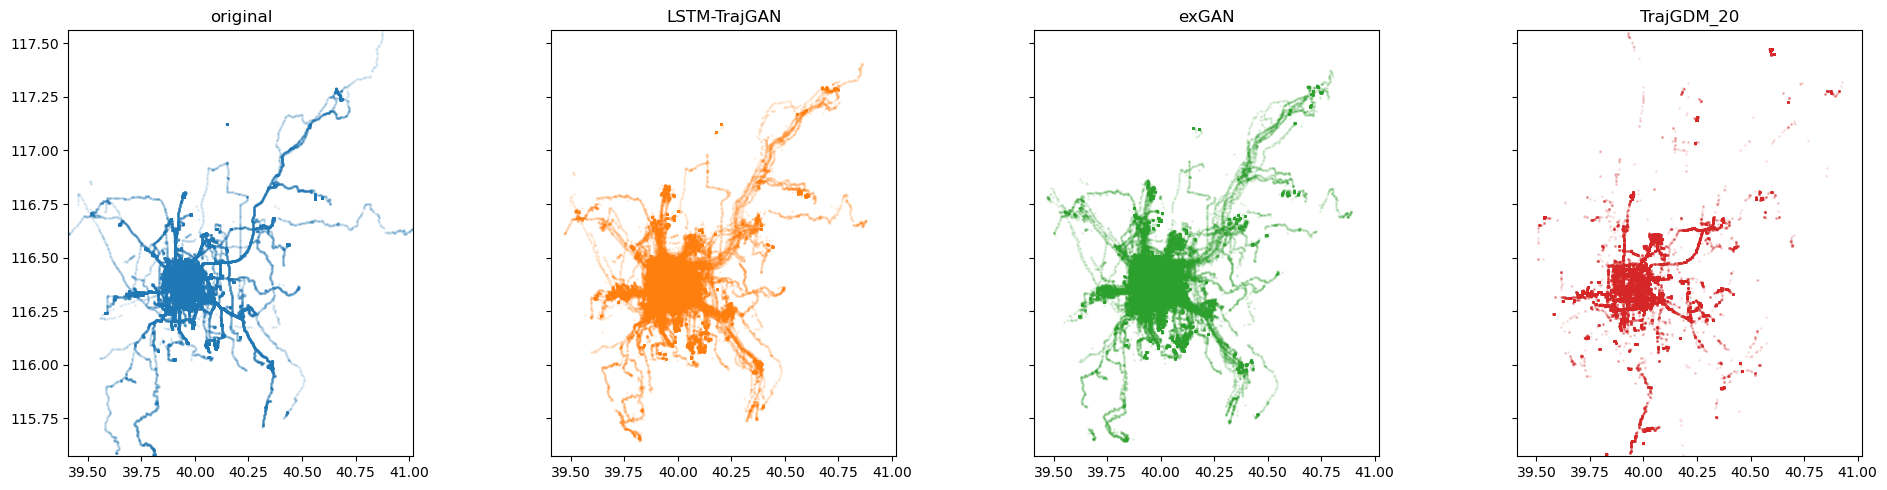

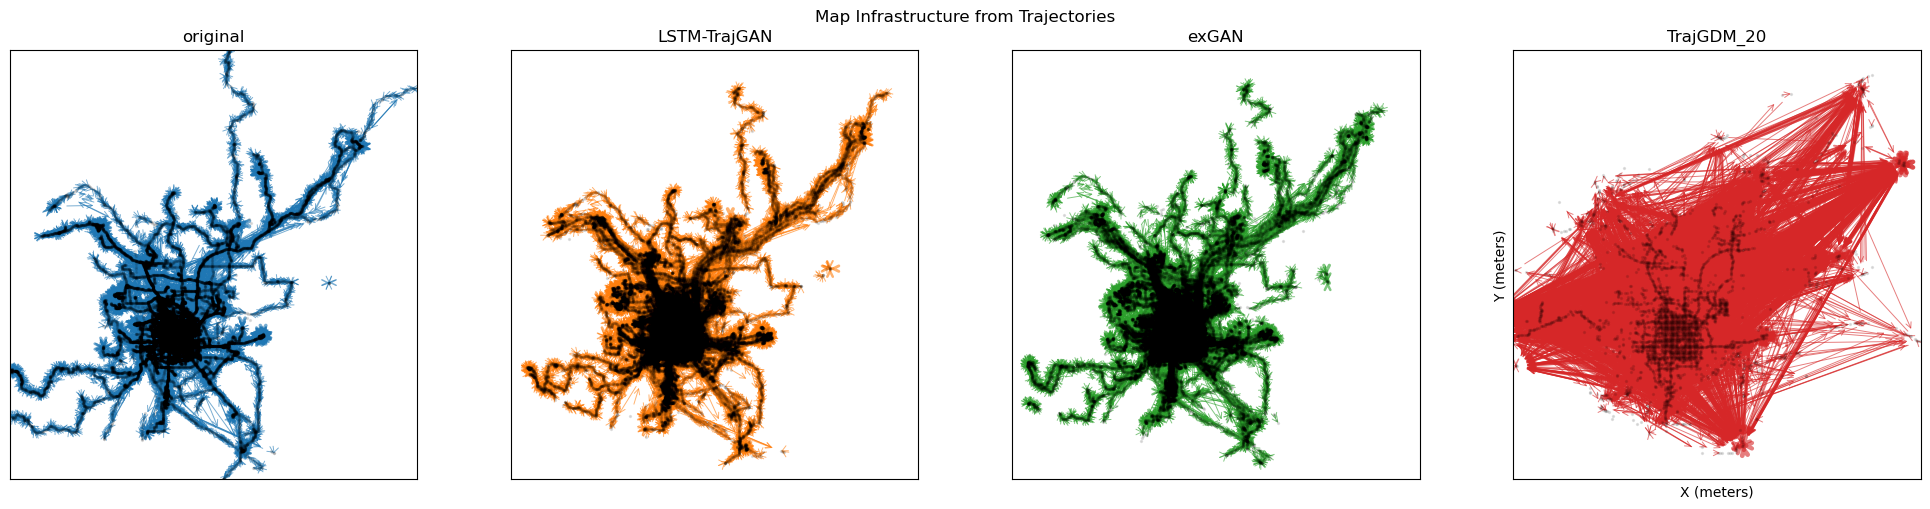

In [ ]:
# the spatial scale in the same across datasets
suite_Hgeo.visualize_point_density()
suite_Hgeo.visualize_map_infrastructure()

#### Weekly geolife

In [6]:
df_original_Wgeo = pd.read_csv(r"..\..\\Data\weekly_geolife\test_latlon.csv")

df_syn_Wgeo_LSTMTraj_best = pd.read_csv(
    r"../gen_data/LSTM-TrajGAN/syn_traj_test_weekly_geolife_3000.csv"
)
df_syn_Wgeo_exGAN_best = pd.read_csv(
    r"../gen_data/exGAN/syn_traj_test_4_weekly_geolife_3000.csv"
)

df_syn_Wgeo_TrajGDM_best_20 = pd.read_csv(
    r"D:\XX\XX\code\TrajGDM_afterpaper\datasets\weekly_geolife\syn_traj_test_l20_e460.csv"
)

df_original_Wgeo = uniform_datetime_df(df_original_Wgeo, hour_col="hour", day_col="day")
df_syn_Wgeo_LSTMTraj_best = uniform_datetime_df(
    df_syn_Wgeo_LSTMTraj_best, hour_col="hour", day_col="day"
)
df_syn_Wgeo_exGAN_best = uniform_datetime_df(
    df_syn_Wgeo_exGAN_best, hour_col="hour", day_col="day"
)

In [7]:
params = EvalParams(cell_width_m=600, cell_height_m=600)
orig_Wgeo = TrajectoryDataset(
    df=df_original_Wgeo,
    dataset_name="original",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)
LSTM_Traj_Wgeo = TrajectoryDataset(
    df=df_syn_Wgeo_LSTMTraj_best,
    dataset_name="LSTM-TrajGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)

exGAN_Wgeo = TrajectoryDataset(
    df=df_syn_Wgeo_exGAN_best,
    dataset_name="exGAN",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
    datetime_col="datetime",
    semantic_category_col="category",
)


TrajGDM20_Wgeo = TrajectoryDataset(
    df=df_syn_Wgeo_TrajGDM_best_20,
    dataset_name="TrajGDM_20",
    lon_col="lon",
    lat_col="lat",
    trajectoryid_col="tid",
)


synthetics_Wgeo = [orig_Wgeo, LSTM_Traj_Wgeo, exGAN_Wgeo, TrajGDM20_Wgeo]

suite_Wgeo = EvaluationSuite(
    original=orig_Wgeo,
    synthetics=synthetics_Wgeo,
    params=params,
    data_name="weekly_geolife",
)

Spatial sensitivity analysis on Original data...
Optimal cell edge length is somewhere between: 535m and 1510m
Midpoint cel edge: 610m with a step to grid ratio (SGR) of 2.7437855676119844 


In [ ]:
# # ******* Trajectory-level metrics ********
traj_results_Wgeo = {}
traj_results_Wgeo["average speed (km/h)"] = suite_Wgeo.evaluate_average_speed()
traj_results_Wgeo["pairwise Hausdorff (WD)"] = (
    suite_Wgeo.evaluate_pairwise_trajectory_dist(
        distance="hausdorff", normalize_0_1=True, n_jobs=-1
    )
)
traj_results_Wgeo["evaluate_map_reconstruction (mean distance)"] = (
    suite_Wgeo.evaluate_traj_network_displacement(on_road_key=0, verbose = False)
)

traj_results_Wgeo["next loc pred (mean accuracy)"] = [
    data_result["mean topk accuracy"]
    for data_result in suite_Wgeo.evaluate_trajectory_next_location_prediction(
        k=10, normalize_0_1=True
    )
]

# ***************** Point-level metrics ********
point_results_Wgeo = {}
point_results_Wgeo["G-rank (tau)"] = suite_Wgeo.evaluate_G_rank(n_cat=10)
point_results_Wgeo["transition prob (WD)"] = suite_Wgeo.evaluate_transtion_matrix(
    normalize_0_1=True
)
point_results_Wgeo["location plausability rate"] = [
    data_result["Implausibility_rate"]
    for data_result in suite_Wgeo.evaluate_location_plausibility(verbose = False)
]

point_results_Wgeo["global flow pred (wd)"] = [
    data_result["Sequential_Flow_WD"]
    for data_result in suite_Wgeo.evaluate_global_flow_prediction(normalize_0_1=True)
]

D:\XX\XX\code\utileval_traj\syntraj_utileval\stats\spatio_temporal.py:58: UserWarning: A column for the temporal attribute was not recognized. If it exists, enter the column's name in TrajectoryDataset. Otherwise, the code will not break but the results will be None.
  warnings.warn(


**Finished calculating average_speed in 0 minutes 0 seconds**
**Finished calculating pairwise_trajectory_dist in 0 minutes 45 seconds**


13668it [00:00, 39842.95it/s]


number of component 32
**Finished calculating map_reconstruction in 2 minutes 51 seconds**
**Finished calculating trajectory_next_location_prediction in 0 minutes 4 seconds**
**Finished calculating G_rank in 0 minutes 0 seconds**
**Finished calculating transtion_matrix in 0 minutes 3 seconds**
**Finished calculating location_plausibility in 0 minutes 58 seconds**
**Finished calculating global_flow_prediction in 0 minutes 41 seconds**


In [10]:
Wgeo_traj_results_df = show_results(
    traj_results_Wgeo,
    [d.dataset_name for d in suite_Wgeo.synthetics],
    suite_Wgeo.data_name,
    header="Trajectory level",
)
display(Wgeo_traj_results_df.round(4))
Wgeo_point_results_df = show_results(
    point_results_Wgeo,
    [d.dataset_name for d in suite_Wgeo.synthetics],
    suite_Wgeo.data_name,
    header="Point level",
)
display(Wgeo_point_results_df.round(4))

,average speed (km/h),pairwise Hausdorff (WD),evaluate_map_reconstruction (mean distance),next loc pred (mean accuracy)
0,,Trajectory level (weekly_geolife),,
original,0.0,0.0,0.055856,0.528696
LSTM-TrajGAN,0.242509,0.001617,0.147875,0.273779
exGAN,0.113568,0.002887,0.18792,0.115396
TrajGDM_20,N/A,0.074421,0.272617,0.155257


,G-rank (tau),transition prob (WD),location plausability rate,global flow pred (wd)
0,,Point level (weekly_geolife),,
original,1.0,0.0,0.002471,0.005638
LSTM-TrajGAN,0.206352,0.09093,0.01676,0.010252
exGAN,0.039266,0.186857,0.024038,0.018449
TrajGDM_20,-0.025497,0.299362,0.018196,0.01972


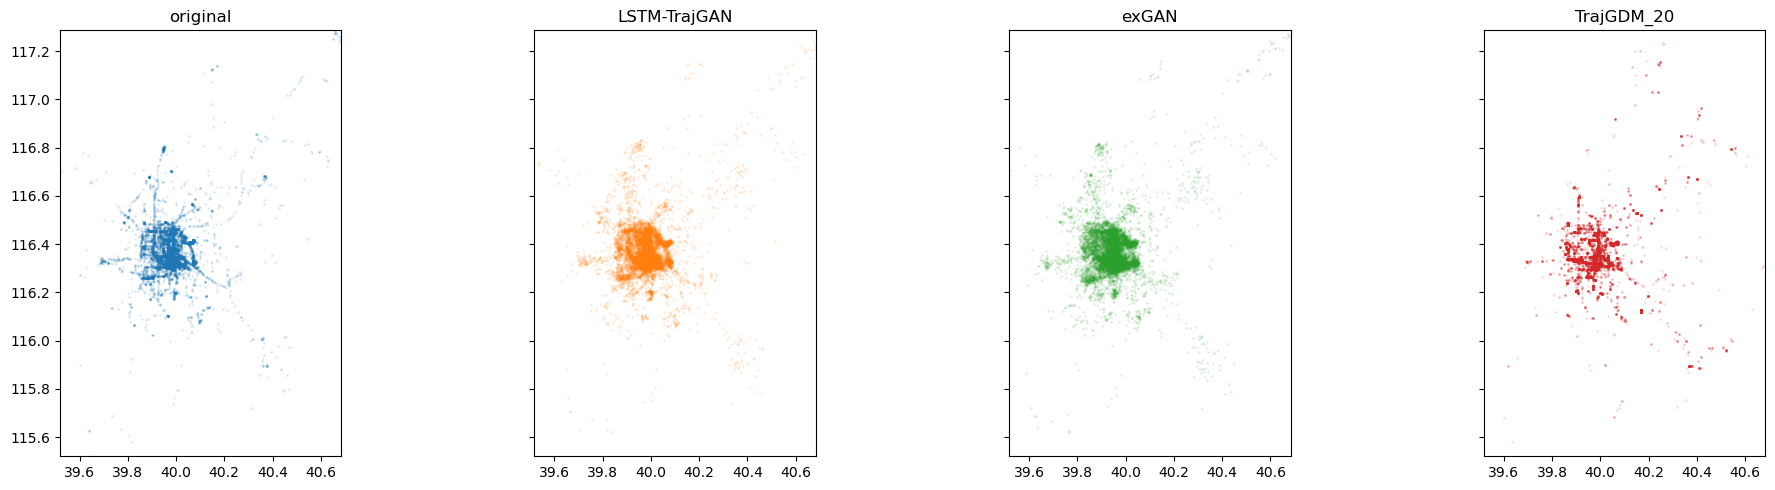

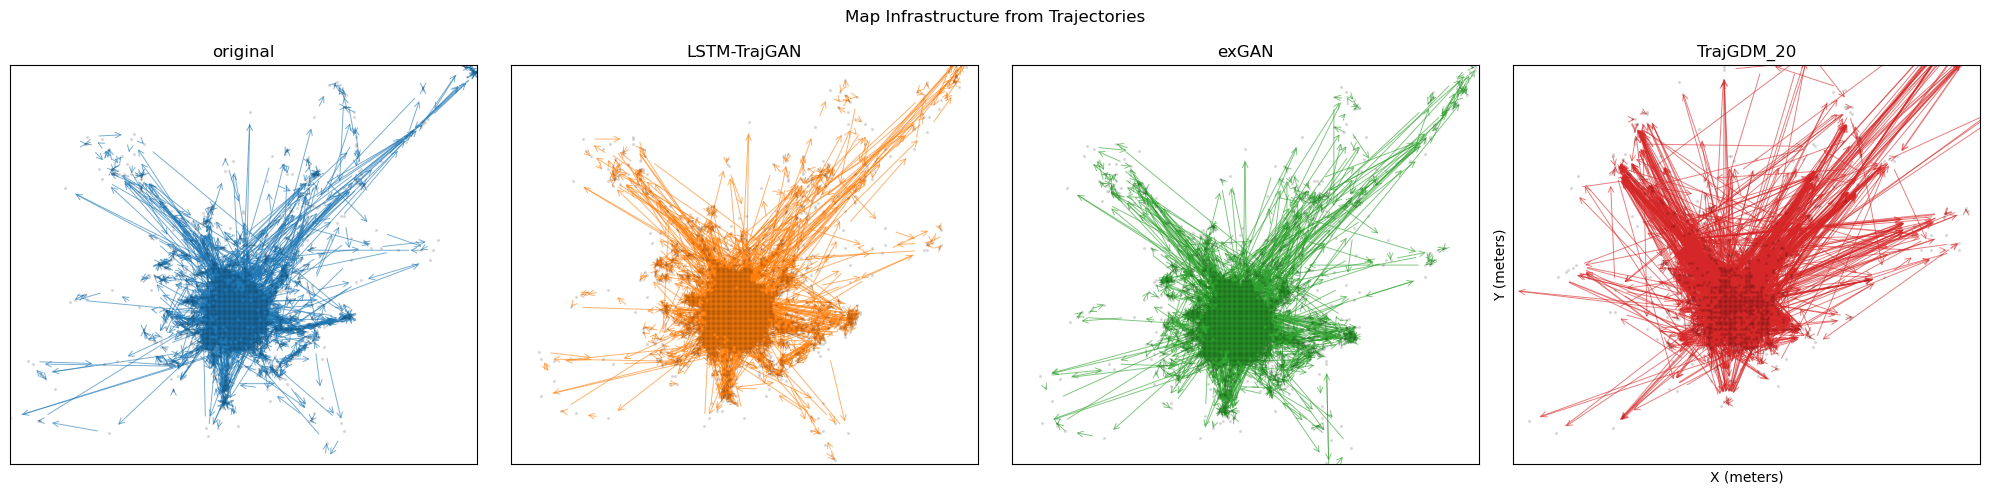

In [ ]:
# the spatial scale in the same across datasets
suite_Wgeo.visualize_point_density()
suite_Wgeo.visualize_map_infrastructure()